In [ ]:
#!uv add causal-learn
#!uv add graphviz
#sudo apt-get update && sudo apt-get install -y graphviz

In [1]:
from aml_working_paper.config import INTERIM_DATA_DIR, RAW_DATA_DIR
from aml_working_paper.data.preprocess import preprocess_data
from aml_working_paper.routing.routing_investigate import select_investigations
from aml_working_paper.causal.local_sample import prepare_local_windows
from aml_working_paper.causal.discovery_data import prepare_discovery_data
from aml_working_paper.causal.discovery import discover_pc, discover_fci
from aml_working_paper.causal.ground_truth import get_ground_truth
from aml_working_paper.causal.evaluation import evaluate_skeleton, summarize_causal_results

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import io
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from causallearn.utils.GraphUtils import GraphUtils

### 1. Load data, process it and define observable variables

In [2]:
routing_df = pd.read_parquet("{}/routing_df.parquet".format(INTERIM_DATA_DIR))
candidates = pd.read_parquet("{}/candidates.parquet".format(INTERIM_DATA_DIR))
df_aml = pd.read_csv("{}/synthetic_df_aml.csv".format(RAW_DATA_DIR))

In [3]:
train_df, val_df, test_df, train_sequences, val_sequences, test_sequences, scaler = preprocess_data(df_aml)

In [4]:
features = [ "economic_context", "account_exposure", "structuring_score", "cross_border_ratio", "transaction_volume"]

### 2. Use routing to select windows using uncertainty

In [5]:
selected = select_investigations(candidates, budget=10, strategy="uncertainty",)
local_windows = prepare_local_windows(data=val_df, selected=selected, features=features)

In [6]:
selected.head()

,account_id,start_time,end_time,start_idx,end_idx,uncertainty,surprise,routing_score
0,55.0,18.0,27.0,18.0,27.0,0.634404,3.753619,0.634404
1,15.0,70.0,79.0,70.0,79.0,0.633793,3.955954,0.633793
2,30.0,30.0,39.0,30.0,39.0,0.633279,3.846830,0.633279
3,80.0,90.0,99.0,90.0,99.0,0.633250,3.741981,0.633250
4,53.0,79.0,88.0,79.0,88.0,0.631723,4.684777,0.631723


In [7]:
pd.DataFrame(local_windows[0]["data"])

,time,economic_context,account_exposure,structuring_score,cross_border_ratio,transaction_volume
18,18,-0.985434,0.061948,0.600674,0.311376,23.353993
19,19,-0.712667,0.074647,0.653479,0.340143,29.255242
20,20,-0.030768,0.205329,0.337485,0.255258,13.256029
21,21,-0.709335,0.080911,0.574244,0.112332,13.762872
22,22,-0.344557,0.047874,0.315098,0.187702,18.888078
23,23,0.358036,0.141916,0.765080,0.247261,26.361263
24,24,0.699606,0.081910,0.531208,0.605016,20.704120
25,25,0.790572,0.143995,0.486489,0.460297,22.683449
26,26,0.100495,0.102052,0.900002,0.322075,25.158210
27,27,-0.292715,0.271902,0.145264,0.126063,17.140852


#### 3. Check window 1 (0) and the behaviour of the observed values

In [8]:
window_0 = local_windows[0]["data"]
subplot_titles = ("Economic context", "Account Exposure", "Structuring Score", "Cross Border Ratio", "Transaction Volume")  # add titles for rows 3, 4, 5 if needed
fig = make_subplots(rows=5, cols=1, shared_xaxes=True, subplot_titles=subplot_titles)
traces_config = [(window_0["economic_context"], 1), (window_0["account_exposure"], 2), (window_0["structuring_score"], 3), (window_0["cross_border_ratio"], 4), (window_0["transaction_volume"], 5) ]

for column, col_num in traces_config:
  fig.add_trace(go.Scatter(x=window_0["time"], y=column, mode="lines"), row=col_num, col=1)

fig.update_layout(height=1200)
fig.show()

### 4. Check the ground truth

In [13]:
current_edges, temporal_edges = get_ground_truth()

In [14]:
current_edges

[('economic_context', 'account_exposure'),
 ('economic_context', 'transaction_volume'),
 ('account_exposure', 'aml_state'),
 ('account_exposure', 'cross_border_ratio'),
 ('aml_state', 'structuring_score'),
 ('aml_state', 'cross_border_ratio'),
 ('aml_state', 'transaction_volume'),
 ('structuring_score', 'transaction_volume')]

In [15]:
temporal_edges

[('economic_context', 'economic_context', 1), ('aml_state', 'aml_state', 1)]

In [16]:
print("Current edges:", len(current_edges))
print("Temporal edges:", len(temporal_edges))

Current edges: 8
Temporal edges: 2


### 5. Combine windows for causal discovery

In [17]:
discovery_data = prepare_discovery_data(local_windows)
observations = discovery_data[features].to_numpy()

### 6. Apply PC and FCI on the discovery data

In [18]:
variable_names = {"X1": "economic_context", 
         "X2": "account_exposure", 
         "X3": "structuring_score", 
         "X4": "cross_border_ratio", 
         "X5": "transaction_volume"}

In [19]:
pc_graph = discover_pc(discovery_data, features, alpha=0.05)
fci_graph = discover_fci(discovery_data, features, alpha=0.05)

  0%|          | 0/5 [00:00<?, ?it/s]

#### PC

In [20]:
for edge in pc_graph.G.get_graph_edges():
    print(edge)

X1 --- X2
X1 --> X5
X3 --- X4
X3 --> X5
X4 --> X5


In [21]:
### save edges for metrics
pc_edges = []
for edge in pc_graph.G.get_graph_edges():
    edge_text = str(edge)
    for old_name, new_name in variable_names.items():
        edge_text = edge_text.replace(old_name, new_name)
    print(edge_text)
    pc_edges.append(edge_text)

economic_context --- account_exposure
economic_context --> transaction_volume
structuring_score --- cross_border_ratio
structuring_score --> transaction_volume
cross_border_ratio --> transaction_volume


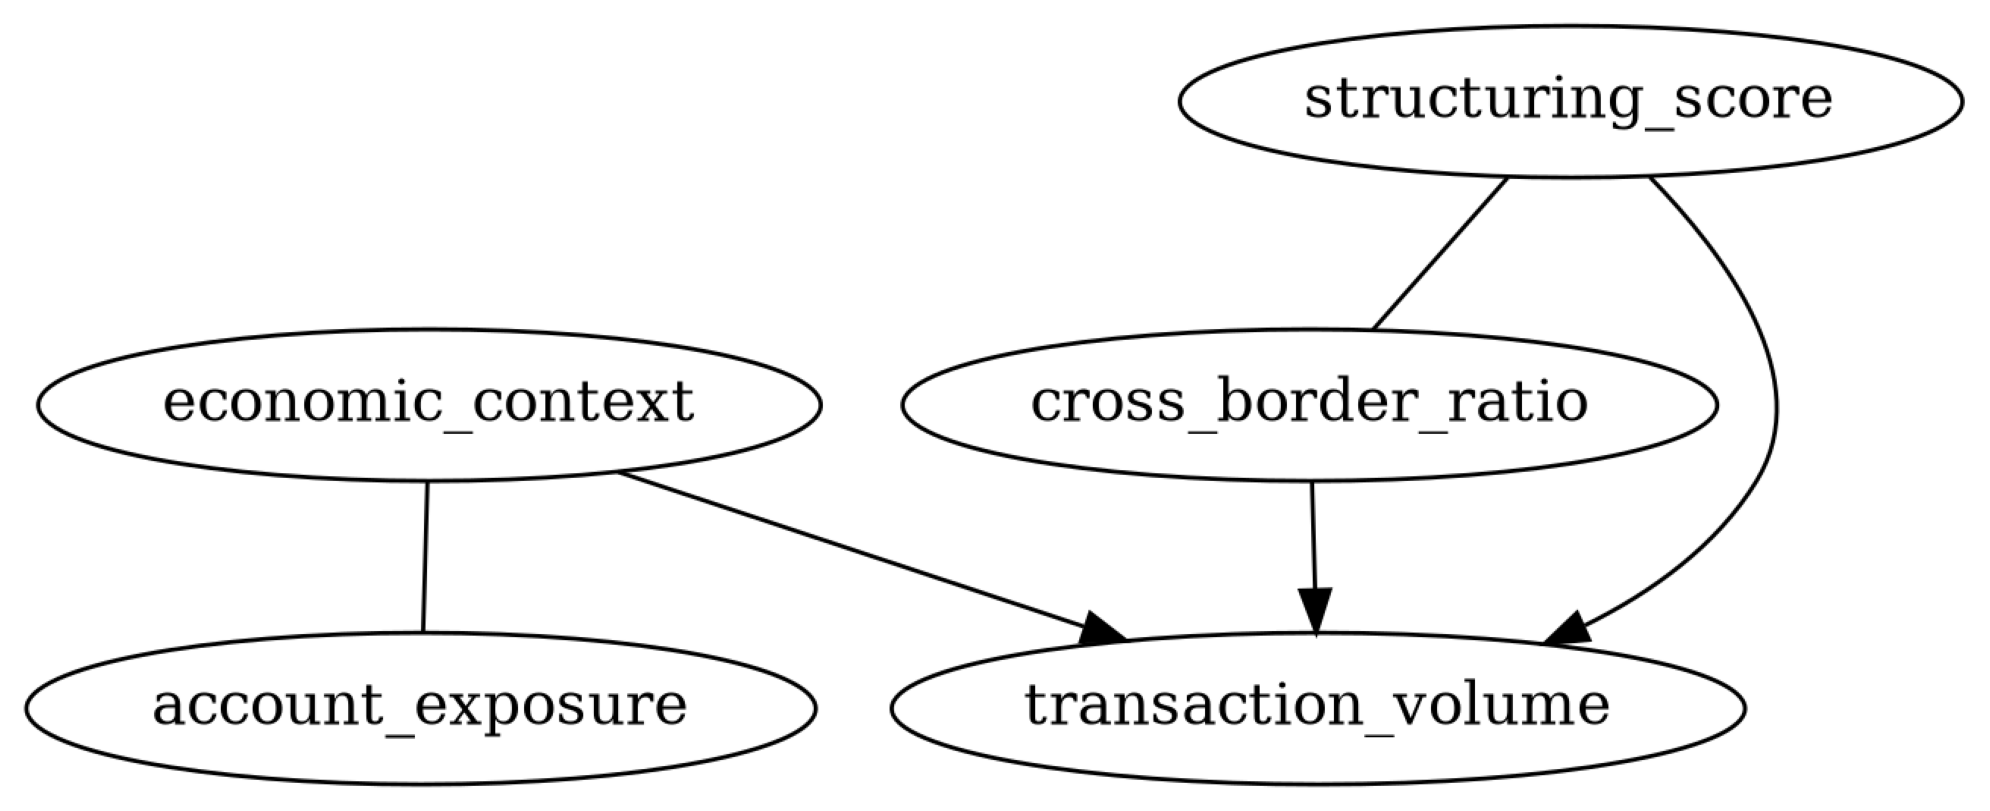

In [22]:
pc_graph.draw_pydot_graph(labels=features)

#### FCI

In [32]:
for edge in fci_graph.get_graph_edges():
    print(edge)

X1 o-o X2
X1 o-> X5
X3 o-o X4
X3 o-> X5
X4 o-> X5


In [33]:
fci_edges = []
for edge in fci_graph.get_graph_edges():
    edge_text = str(edge)
    for old_name, new_name in variable_names.items():
        edge_text = edge_text.replace(old_name, new_name)
    print(edge_text)
    fci_edges.append(edge_text)

economic_context o-o account_exposure
economic_context o-> transaction_volume
structuring_score o-o cross_border_ratio
structuring_score o-> transaction_volume
cross_border_ratio o-> transaction_volume


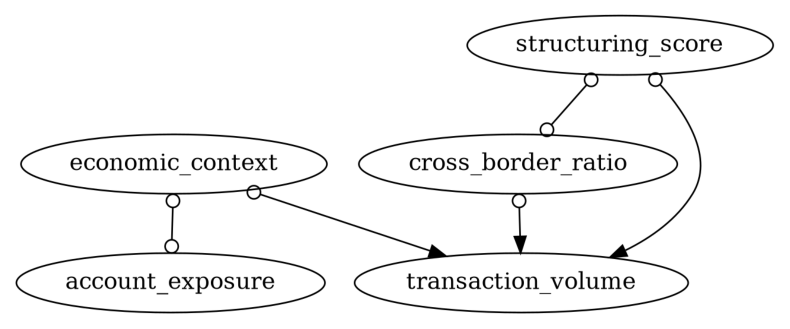

In [34]:
fci_graph = discover_fci(discovery_data, features, alpha=0.05)

pyd = GraphUtils.to_pydot(fci_graph, labels=features)

fp = io.BytesIO(pyd.create_png(f="png"))
img = mpimg.imread(fp, format="png")
plt.figure(figsize=(8, 6))
plt.axis("off")
plt.imshow(img)
plt.show()

#pyd.write_png("fci_causal_graph.png")


### 7. Evaluate relationships

In [27]:
pc_metrics = evaluate_skeleton(pc_edges)

In [28]:
pc_metrics

{'TP': 3,
 'FP': 2,
 'FN': 1,
 'precision': 0.6,
 'recall': 0.75,
 'f1': 0.6666666666666665}

In [35]:
fci_metrics = evaluate_skeleton(fci_edges)

In [36]:
fci_metrics

{'TP': 3,
 'FP': 2,
 'FN': 1,
 'precision': 0.6,
 'recall': 0.75,
 'f1': 0.6666666666666665}

In [ ]:
from aml_working_paper.causal.discovery import discover_pc

features = [
    "economic_context",
    "account_exposure",
    "structuring_score",
    "cross_border_ratio",
    "transaction_volume",
]

graph = discover_pc(
    discovery_data,
    features,
)

print(graph.G.get_graph_edges())

In [ ]:
for edge in graph.G.get_graph_edges():
    print(edge)

In [ ]:
graph = discover_pc(discovery_data, features)

In [ ]:

# Map generic node names to our variables
names = {
    "X1": "economic_context",
    "X2": "account_exposure",
    "X3": "structuring_score",
    "X4": "cross_border_ratio",
    "X5": "transaction_volume",
}

# Print edges using the original variable names
for edge in graph.G.get_graph_edges():

    edge_text = str(edge)

    for old_name, new_name in names.items():
        edge_text = edge_text.replace(old_name, new_name)

    print(edge_text)


In [ ]:
random_selected = select_investigations(
    candidates,
    budget=10,
    strategy="random",
)

random_windows = prepare_local_windows(
    data=val_df,
    selected=random_selected,
    features=features,
)

random_data = prepare_discovery_data(random_windows)

random_graph = discover_pc(random_data, features)

for edge in random_graph.G.get_graph_edges():
    edge_text = str(edge)

    for old_name, new_name in names.items():
        edge_text = edge_text.replace(old_name, new_name)

    print(edge_text)

In [ ]:
strategies = [
    "uncertainty",
    "surprise",
    "combined",
    "random",
]

results = {}

for strategy in strategies:

    # Select investigation windows
    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
    )

    # Recover original observations
    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    # Prepare discovery data
    data = prepare_discovery_data(windows)

    # Run PC
    graph = discover_pc(data, features)

    # Translate edges to original variable names
    edges = []

    for edge in graph.G.get_graph_edges():

        edge_text = str(edge)

        for old_name, new_name in names.items():
            edge_text = edge_text.replace(old_name, new_name)

        edges.append(edge_text)

    results[strategy] = edges

    print(f"\nStrategy: {strategy}")
    print(f"Number of edges: {len(edges)}")

    for edge in edges:
        print(edge)

In [ ]:
true_edges = [
    ("economic_context", "account_exposure"),
    ("economic_context", "transaction_volume"),
    ("account_exposure", "cross_border_ratio"),
    ("structuring_score", "transaction_volume"),
]

In [ ]:

def evaluate_skeleton(discovered, true_edges):
    """Compare discovered connections, ignoring direction."""

    # True connections, without direction
    truth = {frozenset(edge) for edge in true_edges}

    # Discovered connections, without direction
    predicted = set()

    for edge in discovered:

        if " --> " in edge:
            nodes = edge.split(" --> ")
        elif " --- " in edge:
            nodes = edge.split(" --- ")
        elif " <-- " in edge:
            nodes = edge.split(" <-- ")
        else:
            raise ValueError(f"Unknown edge format: {edge}")

        predicted.add(frozenset(nodes))

    # Correctly discovered connections
    tp = len(predicted & truth)

    # Additional and missing connections
    fp = len(predicted - truth)
    fn = len(truth - predicted)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0
    )

    return precision, recall, f1


In [ ]:
for strategy, edges in results.items():

    precision, recall, f1 = evaluate_skeleton(
        edges,
        true_edges,
    )

    print(
        strategy,
        round(precision, 3),
        round(recall, 3),
        round(f1, 3),
    )

In [ ]:
from aml_working_paper.causal.discovery import discover_fci

fci_graph = discover_fci(discovery_data, features)

for edge in fci_graph.get_graph_edges():
    print(edge)

In [ ]:
for edge in fci_graph.get_graph_edges():

    edge_text = str(edge)

    for old_name, new_name in names.items():
        edge_text = edge_text.replace(old_name, new_name)

    print(edge_text)

In [ ]:
fci_results = {}

for strategy in strategies:

    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
    )

    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    data = prepare_discovery_data(windows)

    graph = discover_fci(data, features)

    edges = []

    for edge in graph.get_graph_edges():

        edge_text = str(edge)

        for old_name, new_name in names.items():
            edge_text = edge_text.replace(old_name, new_name)

        edges.append(edge_text)

    fci_results[strategy] = edges

    print(f"\nStrategy: {strategy}")

    for edge in edges:
        print(edge)

In [ ]:
import pandas as pd

from aml_working_paper.causal.evaluation import evaluate_skeleton

summary = []

for method, method_results in [
    ("PC", results),
    ("FCI", fci_results),
]:

    for strategy, edges in method_results.items():

        metrics = evaluate_skeleton(edges)

        summary.append({
            "method": method,
            "strategy": strategy,
            **metrics,
        })

evaluation_df = pd.DataFrame(summary)

print(evaluation_df)

In [ ]:

import pandas as pd

from aml_working_paper.causal.evaluation import evaluate_skeleton

random_results = []

# Repeat random selection with 50 different seeds
for seed in range(42, 92):

    # Select 10 random investigation windows
    selected = select_investigations(
        candidates,
        budget=10,
        strategy="random",
        random_state=seed,
    )

    # Recover the original observations
    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    # Combine the selected observations
    data = prepare_discovery_data(windows)

    # Run PC
    graph = discover_pc(data, features)

    # Get discovered connections
    edges = []

    for edge in graph.G.get_graph_edges():

        edge_text = str(edge)

        for old_name, new_name in names.items():
            edge_text = edge_text.replace(old_name, new_name)

        edges.append(edge_text)

    # Evaluate the discovered skeleton
    metrics = evaluate_skeleton(edges)

    random_results.append({
        "seed": seed,
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
    })

random_df = pd.DataFrame(random_results)

print(random_df.head())


In [ ]:
uncertainty_f1 = 0.75

equal_or_better = (
    random_df["f1"] >= uncertainty_f1
).mean()

print("Random mean F1:", random_df["f1"].mean())
print("Random standard deviation:", random_df["f1"].std())

print(
    "Fraction of random selections >= uncertainty:",
    equal_or_better,
)

In [ ]:
print(random_df["f1"].describe())

print(
    (random_df["f1"] >= 0.75).mean()
)

In [ ]:

import pandas as pd

# Results from our previous PC evaluation
pc_scores = evaluation_df[
    evaluation_df["method"] == "PC"
].set_index("strategy")

# Comparison table
comparison = pd.DataFrame({
    "strategy": [
        "uncertainty",
        "surprise",
        "combined",
        "random",
    ],
    "mean_f1": [
        pc_scores.loc["uncertainty", "f1"],
        pc_scores.loc["surprise", "f1"],
        pc_scores.loc["combined", "f1"],
        random_df["f1"].mean(),
    ],
    "std_f1": [
        0.0,
        0.0,
        0.0,
        random_df["f1"].std(),
    ],
})

print(comparison.round(3))


In [ ]:
for strategy in strategies:

    selected = select_investigations(
        candidates,
        budget=10,
        strategy=strategy,
    )

    windows = prepare_local_windows(
        data=val_df,
        selected=selected,
        features=features,
    )

    data = prepare_discovery_data(windows)

    # Variability within each selected window
    variability = (
        data.groupby("window_id")[features]
        .std()
        .mean()
    )

    print(f"\n{strategy}")
    print(variability.round(3))